# Analisis dan Klasifikasi Sinyal Audio: Suara Berisik vs Non-Berisik

**Mata Kuliah:** Penambangan Sains Data (PSD) / Proyek Sains Data  
**Topik:** Pre-pemrosesan Sinyal Audio, Ekstraksi 13 Koefisien MFCC & Fitur Akustik Librosa, Agregasi Fitur, Seleksi Fitur, Pemodelan Machine Learning (SVM, Random Forest, dll), dan Implementasi Pipeline Inferensi Pengujian Suara  
**Dataset:** Rekaman suara lingkungan kelas **`berisik`** (ramai, gaduh, percakapan banyak orang) dan **`non-berisik`** (hening, tenang, suara latar mesin AC/kipas)  
**Dokumentasi Terkait:**
- 📄 [Dokumen 1: Business Understanding](business_understanding)
- 📄 [Dokumen 2: Data Understanding](data_understanding)

---

## 📖 Pendahuluan dan Metodologi CRISP-DM

Dalam pemrosesan sinyal digital (*Digital Signal Processing / DSP*) dan *Machine Learning*, sinyal suara mentah (*raw waveform audio*) berbentuk sinyal amplitudo terhadap waktu yang kontinu berdimensi sangat besar dengan laju pencuplikan tinggi. Sinyal audio mentah ini tidak dapat langsung diinputkan ke dalam algoritma klasifikasi data tabular konvensional.

Sesuai dengan acuan pada **md.pdf**, fitur MFCC (*Mel-Frequency Cepstral Coefficients*) diekstraksi sebanyak **13 koefisien**, yang dipadukan dengan fitur RMS Energy, Spectral Centroid, dan Zero Crossing Rate (ZCR).

Alur kerja sains data terpadu dari hulu ke hilir:

```
┌────────────────────────────────────────────────────────────────────────┐
│                   ALUR LENGKAP SAINS DATA AUDIO                        │
├────────────────────────────────────────────────────────────────────────┤
│ 1. Pra-pemrosesan Sinyal Mentah                                        │
│    (Resample 22.050 Hz ➔ Buang Jeda Hening ➔ Segmentasi Chunk 3 Detik) │
│                                  │                                     │
│                                  ▼                                     │
│ 2. Ekstraksi Fitur Librosa (RMS, Centroid, ZCR, 13 Koefisien MFCC)     │
│                                  │                                     │
│                                  ▼                                     │
│ 3. Agregasi Statistik (Mean & Std RMS/Centroid/ZCR + 13 MFCC ➔ 19 Fitur)│
│                                  │                                     │
│                                  ▼                                     │
│ 4. Penggabungan & Pembagian Data (Stratified Split 80:20 Train/Test)   │
│                                  │                                     │
│                                  ▼                                     │
│ 5. Seleksi Fitur Akustik (MDI Random Forest & Uji Univariat ANOVA F)   │
│                                  │                                     │
│                                  ▼                                     │
│ 6. Pemodelan & Komparasi Algoritma Klasifikasi                         │
│    (Random Forest, SVM RBF, SVM Linear, KNN, LogReg, Gradient Boosting)│
│                                  │                                     │
│                                  ▼                                     │
│ 7. Evaluasi Komparatif & Penentuan Model Terbaik                       │
│    (Leaderboard, Confusion Matrix, Kurva ROC-AUC)                      │
│                                  │                                     │
│                                  ▼                                     │
│ 8. Implementasi Pipeline Inferensi / Uji Suara Baru Real-Time          │
│    (Pengecekan Audio Otomatis Berisik vs Non-Berisik & Persistensi PKL)│
└────────────────────────────────────────────────────────────────────────┘
```


---
## 1. Persiapan Lingkungan dan Impor Library

Langkah pertama adalah mengimpor pustaka-pustaka Python yang diperlukan:
- **`os` & `glob`**: Navigasi struktur direktori file audio dan manajemen berkas keluaran (*output CSV*).
- **`numpy` & `pandas`**: Komputasi numerik array multidimensi dan manipulasi tabel data (*DataFrame*).
- **`librosa` & `librosa.display`**: Pustaka standar industri untuk analisis sinyal audio, komputasi spektrogram, dan ekstraksi fitur akustik.
- **`matplotlib.pyplot` & `seaborn`**: Visualisasi bentuk gelombang sinyal (*waveform*), spektrogram frekuensi, sebaran fitur (*boxplot*), dan profil MFCC.
- **`sklearn.model_selection.train_test_split`**: Pembagian dataset latih dan uji secara terstratifikasi (*stratified split*).


In [4]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from sklearn.model_selection import train_test_split

# Filter peringatan agar tampilan notebook rapi
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Konfigurasi Path Direktori Dataset
# Adaptif: mencari folder 'berisik' baik jika dijalankan dari root proyek maupun dari folder materi/audio
if os.path.exists('berisik'):
    CURRENT_DIR = os.path.abspath(os.getcwd())
elif os.path.exists(os.path.join('materi', 'audio', 'berisik')):
    CURRENT_DIR = os.path.abspath(os.path.join('materi', 'audio'))
elif '__file__' in locals() and os.path.exists(os.path.join(os.path.dirname(os.path.abspath(__file__)), 'berisik')):
    CURRENT_DIR = os.path.dirname(os.path.abspath(__file__))
else:
    CURRENT_DIR = os.path.abspath(os.getcwd())

DIR_BERISIK = os.path.join(CURRENT_DIR, 'berisik')
DIR_NON_BERISIK = os.path.join(CURRENT_DIR, 'non-berisik')

print("Direktori Kerja Utama :", CURRENT_DIR)
print("Folder Audio 'berisik'    :", DIR_BERISIK)
print("Folder Audio 'non-berisik':", DIR_NON_BERISIK)



Direktori Kerja Utama : c:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio
Folder Audio 'berisik'    : c:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\berisik
Folder Audio 'non-berisik': c:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\non-berisik


---
## 2. Eksplorasi Dataset Audio Mentah

Sebelum memulai pemrosesan, kita melakukan inventarisasi terhadap seluruh berkas audio yang tersedia di direktori `berisik/` dan `non-berisik/`. 

Kita memeriksa:
1. Jumlah total file audio pada masing-masing kelas.
2. Format ekstensi file (seperti `.mp3` atau `.wav`).
3. Karakteristik metadata audio: durasi audio (detik) dan laju pencuplikan bawaan (*native sampling rate* dalam Hz).


In [5]:
def scan_audio_files(directory):
    """Memindai dan mengembalikan daftar file audio valid dari direktori."""
    valid_exts = ('.mp3', '.wav', '.ogg', '.flac', '.m4a')
    files = [
        os.path.join(directory, f)
        for f in sorted(os.listdir(directory))
        if f.lower().endswith(valid_exts)
    ]
    return files

files_berisik = scan_audio_files(DIR_BERISIK)
files_non_berisik = scan_audio_files(DIR_NON_BERISIK)

print(f"Jumlah sampel kelas 'berisik'    : {len(files_berisik)} file")
print(f"Jumlah sampel kelas 'non-berisik': {len(files_non_berisik)} file")
print(f"Total seluruh sampel audio       : {len(files_berisik) + len(files_non_berisik)} file")

# Inspeksi sampel metadata
print("\n--- Sampel Karakteristik Audio Mentah ---")
for label, sample_file in [('Berisik', files_berisik[0]), ('Non-Berisik', files_non_berisik[0])]:
    dur = librosa.get_duration(path=sample_file)
    sr = librosa.get_samplerate(sample_file)
    fname = os.path.basename(sample_file)
    print(f"Kelas [{label:11s}]: '{fname}' | Durasi: {dur:.2f} detik | Native SR: {sr} Hz")



Jumlah sampel kelas 'berisik'    : 101 file
Jumlah sampel kelas 'non-berisik': 100 file
Total seluruh sampel audio       : 201 file

--- Sampel Karakteristik Audio Mentah ---
Kelas [Berisik    ]: '24-003 berisik (1).mp3' | Durasi: 30.04 detik | Native SR: 44100 Hz
Kelas [Non-Berisik]: '24-003 sunyi 2.mp3' | Durasi: 30.00 detik | Native SR: 44100 Hz


---
## 3. Teori dan Konsep Pre-Pemrosesan Audio

Data audio mentah dari berbagai sumber perekaman memiliki variasi teknis yang signifikan (misalnya laju cuplik berbeda, adanya hening panjang di awal/akhir rekaman, dan variasi durasi). Untuk memastikan konsistensi dan integritas analisis, kita menerapkan tiga langkah pre-pemrosesan berurutan:

### A. Resampling (Pencuplikan Ulang ke 22.050 Hz)
- **Definisi:** Mengubah laju pencuplikan (*sampling rate*, $f_s$) dari laju asal (misal $44.100\text{ Hz}$ atau $48.000\text{ Hz}$) menjadi **$22.050\text{ Hz}$**.
- **Landasan Teori (Teorema Nyquist-Shannon):**
  $$f_s \ge 2 \cdot f_{\max}$$
  Dengan laju $22.050\text{ Hz}$, frekuensi batas Nyquist adalah $\approx 11.025\text{ Hz}$. Rentang ini mencakup seluruh energi frekuensi fundamental dan harmonik ucapan manusia serta kebisingan lingkungan (*environmental ambient noise*), sekaligus mereduksi separuh beban komputasi dan memori array.

### B. Buang Hening (*Silence Removal*)
- **Definisi:** Menghapus bagian-bagian sinyal yang tidak memiliki aktivitas suara bermakna (bagian hening atau *background pause*).
- **Metode:** Menggunakan algoritma pemisahan energi desibel `librosa.effects.split(y, top_db=25)`:
  - Sinyal dianalisis dalam jendela frame pendek.
  - Frame dengan tingkat energi kurang dari $25\text{ dB}$ di bawah energi puncak ($top\_db = 25$) diklasifikasikan sebagai hening (*silence*).
  - Seluruh segmen aktif (*non-silent intervals*) kemudian disambungkan kembali (*concatenated*) menjadi sinyal aktif yang padat informasi.

### C. Chunking (Segmentasi Sinyal Berdurasi Tetap)
- **Definisi:** Membagi sinyal aktif menjadi segmen-segmen potongan (*chunk*) dengan durasi seragam, yaitu **$3\text{ detik}$** ($3 \times 22.050 = 66.150\text{ sampel}$).
- **Alasan Metodologis:**
  1. **Keseragaman Temporal:** Memastikan setiap unit observasi yang dianalisis memiliki panjang dan resolusi waktu yang konsisten.
  2. **Kestabilan Fitur:** Menghindari bias akibat rekaman yang memiliki panjang durasi yang tidak seragam.


In [6]:
# Parameter Standar Pre-pemrosesan
TARGET_SR = 22050          # Frekuensi pencuplikan target (Hz)
TOP_DB = 25                # Threshold buang hening (dB di bawah puncak)
CHUNK_DURATION = 3         # Durasi per chunk (detik)
CHUNK_SAMPLES = TARGET_SR * CHUNK_DURATION  # 66.150 sampel per chunk

def load_and_resample(file_path, sr=TARGET_SR):
    """
    Memuat file audio dan melakukan resampling otomatis ke frekuensi TARGET_SR.
    """
    y, sr_loaded = librosa.load(file_path, sr=sr)
    return y, sr_loaded

def remove_silence(y, top_db=TOP_DB):
    """
    Mendeteksi dan mengeliminasi segmen hening pada audio berdasarkan ambang batas top_db.
    Menggabungkan kembali seluruh interval aktif non-silent.
    """
    intervals = librosa.effects.split(y, top_db=top_db)
    if len(intervals) == 0:
        return y
    y_trimmed = np.concatenate([y[start:end] for start, end in intervals])
    return y_trimmed

def chunk_audio(y, chunk_samples=CHUNK_SAMPLES):
    """
    Membagi sinyal audio menjadi segmen berdurasi tetap (chunk_samples).
    Jika durasi total < 1 chunk, dilakukan padding nol agar dimensi tetap konsisten.
    """
    n_samples = len(y)
    chunks = []
    for start in range(0, n_samples - chunk_samples + 1, chunk_samples):
        chunk = y[start : start + chunk_samples]
        chunks.append(chunk)
        
    # Penanganan edge case jika durasi setelah buang hening < chunk_samples
    if len(chunks) == 0 and n_samples > 0:
        pad_width = chunk_samples - n_samples
        padded = np.pad(y, (0, pad_width), mode='constant')
        chunks.append(padded)
        
    return chunks

print("Fungsi 'load_and_resample', 'remove_silence', dan 'chunk_audio' berhasil diinisialisasi.")



Fungsi 'load_and_resample', 'remove_silence', dan 'chunk_audio' berhasil diinisialisasi.


---
### Visualisasi Komparasi Bentuk Gelombang (*Waveform*) Pre-Pemrosesan

Grafik di bawah ini mengilustrasikan perubahan sinyal audio sebelum dan sesudah tahapan pembuangan hening (*silence removal*), serta pembagian garis vertikal merah yang menandai batasan segmen *chunk* berdurasi 3 detik untuk sampel audio `berisik` dan `non-berisik`.


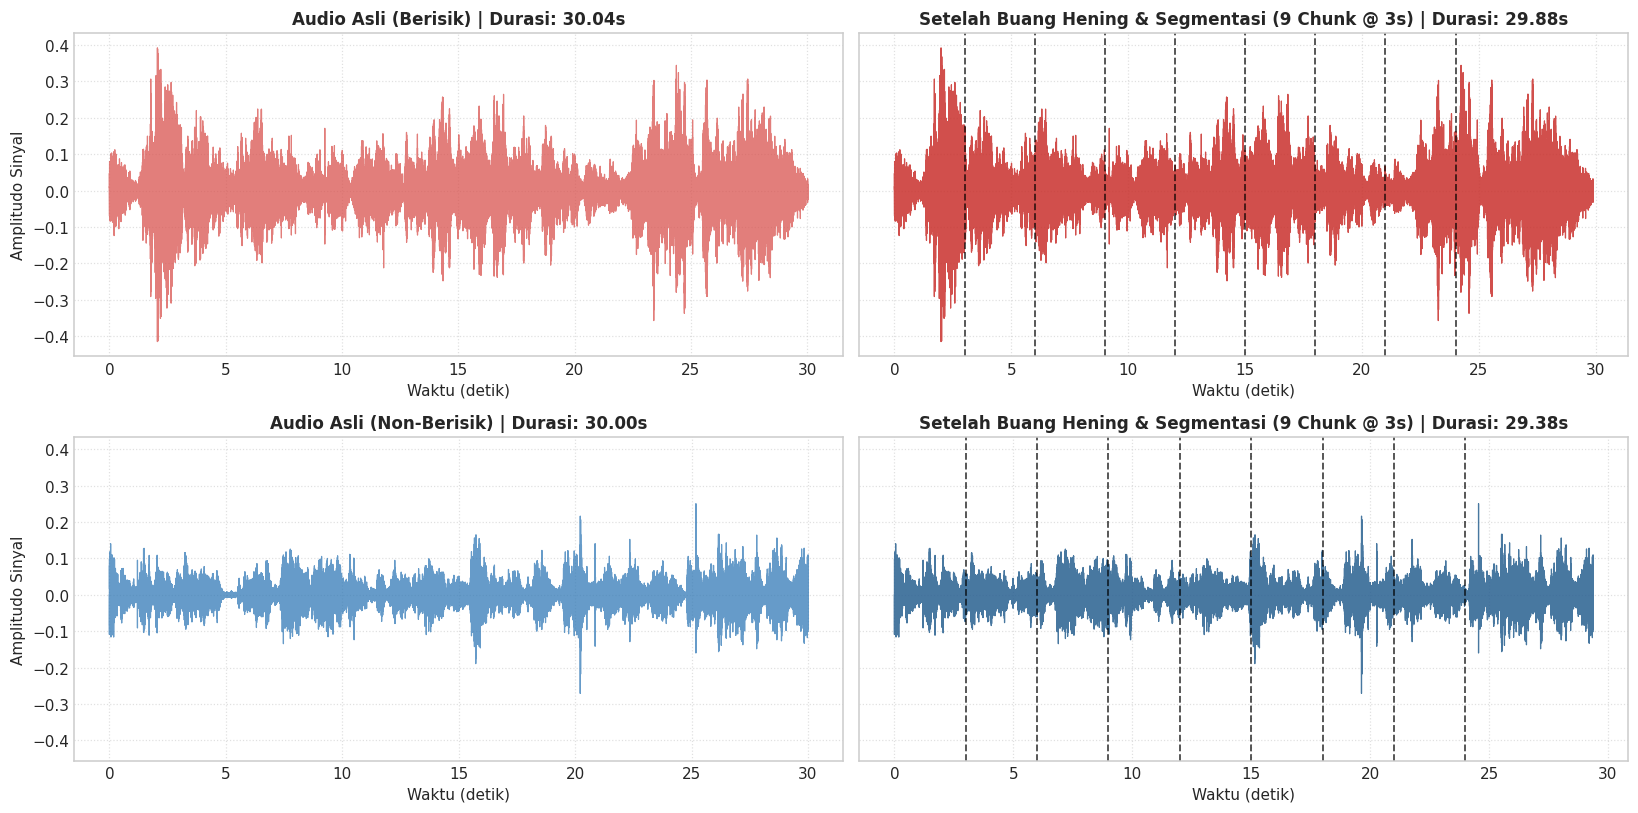

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharey=True)

demo_cases = [
    ('Berisik', files_berisik[0], '#d9534f', '#c9302c'),
    ('Non-Berisik', files_non_berisik[0], '#337ab7', '#286090')
]

for row_idx, (label, fpath, col1, col2) in enumerate(demo_cases):
    y_orig, _ = load_and_resample(fpath, sr=TARGET_SR)
    y_clean = remove_silence(y_orig, top_db=TOP_DB)
    chunks = chunk_audio(y_clean, chunk_samples=CHUNK_SAMPLES)
    
    t_orig = np.linspace(0, len(y_orig) / TARGET_SR, len(y_orig))
    t_clean = np.linspace(0, len(y_clean) / TARGET_SR, len(y_clean))
    
    # 1. Waveform Asli
    axes[row_idx, 0].plot(t_orig, y_orig, color=col1, alpha=0.75, linewidth=0.8)
    axes[row_idx, 0].set_title(f"Audio Asli ({label}) | Durasi: {len(y_orig)/TARGET_SR:.2f}s", fontsize=11, fontweight='bold')
    axes[row_idx, 0].set_xlabel("Waktu (detik)")
    axes[row_idx, 0].set_ylabel("Amplitudo Sinyal")
    axes[row_idx, 0].grid(True, linestyle=':', alpha=0.6)
    
    # 2. Waveform Setelah Buang Hening & Chunk
    axes[row_idx, 1].plot(t_clean, y_clean, color=col2, alpha=0.85, linewidth=0.8)
    for c_i in range(1, len(chunks)):
        axes[row_idx, 1].axvline(x=c_i * CHUNK_DURATION, color='black', linestyle='--', alpha=0.7, linewidth=1.2)
        
    axes[row_idx, 1].set_title(f"Setelah Buang Hening & Segmentasi ({len(chunks)} Chunk @ 3s) | Durasi: {len(y_clean)/TARGET_SR:.2f}s", 
                               fontsize=11, fontweight='bold')
    axes[row_idx, 1].set_xlabel("Waktu (detik)")
    axes[row_idx, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()



---
## 4. Teori Ekstraksi Fitur Akustik dengan Librosa

Untuk mengukur perbedaan fisik dan psikoakustik antara suara lingkungan ramai (*berisik*) dan suara hening/tenang (*non-berisik*), kita mengekstrak grup fitur akustik fundamental sesuai acuan **md.pdf**:

### 1. Root Mean Square (RMS) Energy
- **Formula Matematis:**
  $$\text{RMS} = \sqrt{\frac{1}{N}\sum_{n=1}^{N} x[n]^2}$$
- **Fungsi Fisik:** Mengukur magnitudo energi atau volume sinyal audio. Suasana berisik dengan obrolan banyak orang memiliki RMS yang jauh lebih tinggi dan dinamis dibanding suasana tenang.

### 2. Spectral Centroid
- **Formula Matematis:**
  $$\text{Centroid} = \frac{\sum_{k=1}^K f_k \cdot |X[k]|}{\sum_{k=1}^K |X[k]|}$$
- **Fungsi Fisik:** Titik pusat massa spektrum frekuensi (tingkat *brightness* atau kecerahan suara). Suara percakapan manusia memiliki konsentrasi frekuensi tengah (forman vokal), sedangkan dengung AC terkonsentrasi di frekuensi rendah.

### 3. Zero Crossing Rate (ZCR)
- **Formula Matematis:**
  $$\text{ZCR} = \frac{1}{2N}\sum_{n=1}^{N-1} |\text{sgn}(x[n]) - \text{sgn}(x[n-1])|$$
- **Fungsi Fisik:** Frekuensi perubahan tanda amplitudo sinyal melewati nol. Suara gaduh dan vokal frikatif memiliki nilai ZCR yang lebih tinggi.

### 4. Mel-Frequency Cepstral Coefficients (MFCC - 13 Koefisien)
- Sesuai dengan spesifikasi pada **md.pdf**, kita mengekstrak **13 koefisien MFCC** ($n\_mfcc = 13$).
- **Fungsi Fisik:** Merepresentasikan timbre dan bentuk spektral suara manusia dengan memetakan frekuensi ke skala Mel (meniru kurva sensitivitas koklea telinga manusia). Ini adalah fitur paling efektif untuk membedakan suara percakapan manusia dari suara latar mesin statis.


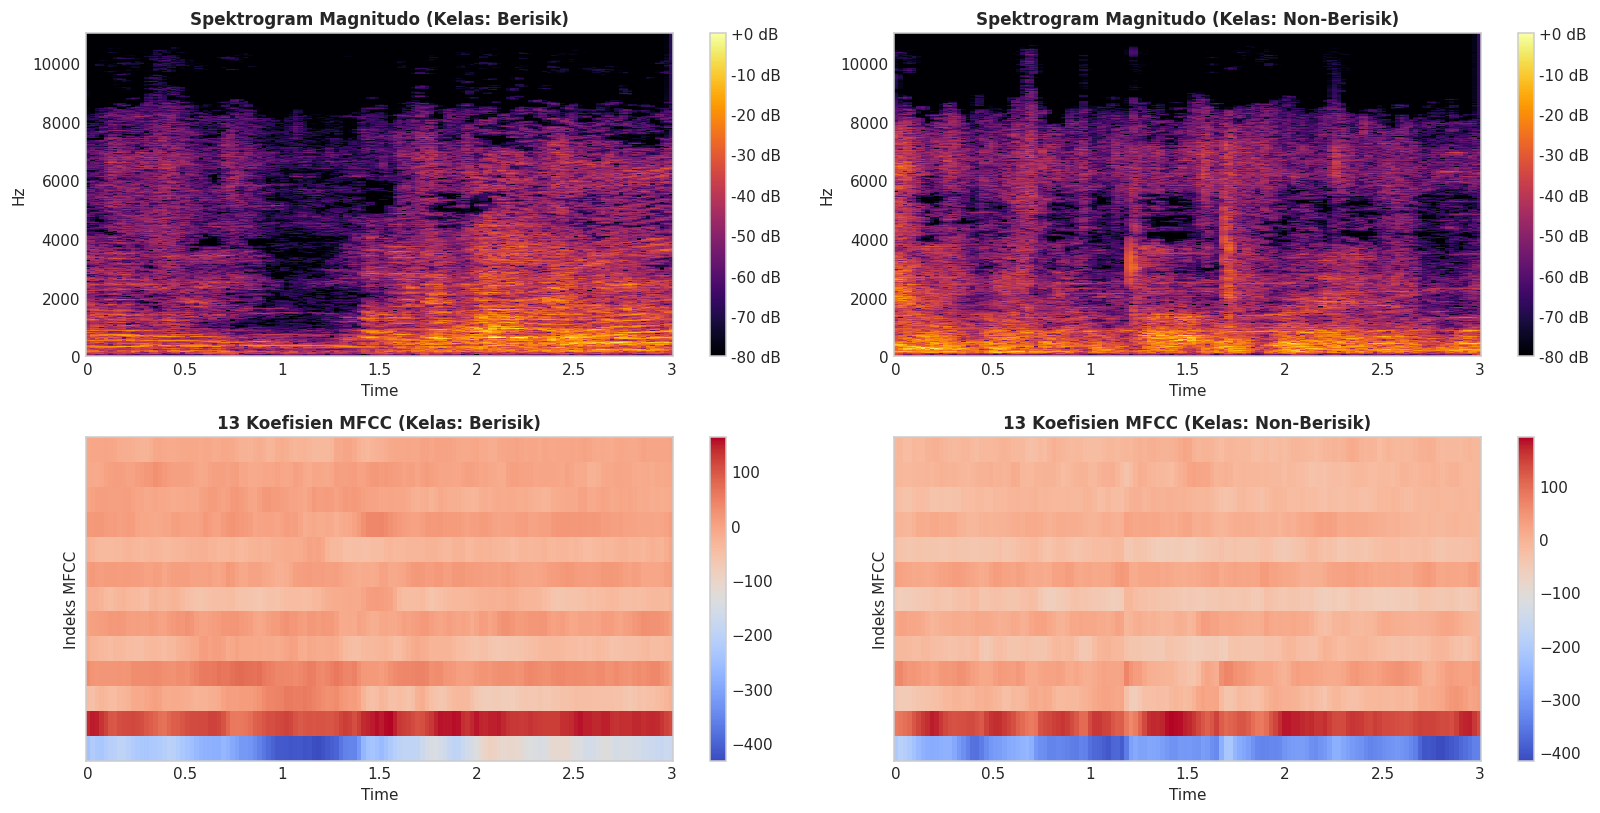

In [8]:
# Ambil 1 sampel chunk (3 detik) dari masing-masing kelas untuk demonstrasi fitur
y_b_demo, _ = load_and_resample(files_berisik[0])
y_nb_demo, _ = load_and_resample(files_non_berisik[0])

chunk_b_demo = y_b_demo[:CHUNK_SAMPLES]
chunk_nb_demo = y_nb_demo[:CHUNK_SAMPLES]

# Hitung Spektrogram STFT
D_b = librosa.amplitude_to_db(np.abs(librosa.stft(chunk_b_demo)), ref=np.max)
D_nb = librosa.amplitude_to_db(np.abs(librosa.stft(chunk_nb_demo)), ref=np.max)

# Hitung 13 Koefisien MFCC
mfcc_b = librosa.feature.mfcc(y=chunk_b_demo, sr=TARGET_SR, n_mfcc=13)
mfcc_nb = librosa.feature.mfcc(y=chunk_nb_demo, sr=TARGET_SR, n_mfcc=13)

# Visualisasi Plotting
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))

# 1. Spektrogram Berisik
img1 = librosa.display.specshow(D_b, sr=TARGET_SR, x_axis='time', y_axis='hz', ax=axes[0, 0], cmap='inferno')
axes[0, 0].set_title("Spektrogram Magnitudo (Kelas: Berisik)", fontsize=11, fontweight='bold')
fig.colorbar(img1, ax=axes[0, 0], format="%+2.0f dB")

# 2. Spektrogram Non-Berisik
img2 = librosa.display.specshow(D_nb, sr=TARGET_SR, x_axis='time', y_axis='hz', ax=axes[0, 1], cmap='inferno')
axes[0, 1].set_title("Spektrogram Magnitudo (Kelas: Non-Berisik)", fontsize=11, fontweight='bold')
fig.colorbar(img2, ax=axes[0, 1], format="%+2.0f dB")

# 3. Heatmap MFCC Berisik
img3 = librosa.display.specshow(mfcc_b, sr=TARGET_SR, x_axis='time', ax=axes[1, 0], cmap='coolwarm')
axes[1, 0].set_title("13 Koefisien MFCC (Kelas: Berisik)", fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel("Indeks MFCC")
fig.colorbar(img3, ax=axes[1, 0])

# 4. Heatmap MFCC Non-Berisik
img4 = librosa.display.specshow(mfcc_nb, sr=TARGET_SR, x_axis='time', ax=axes[1, 1], cmap='coolwarm')
axes[1, 1].set_title("13 Koefisien MFCC (Kelas: Non-Berisik)", fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel("Indeks MFCC")
fig.colorbar(img4, ax=axes[1, 1])

plt.tight_layout()
plt.show()



---
## 5. Teori dan Implementasi Agregasi Fitur (*Feature Aggregation*)

### Mengapa Agregasi Diperlukan?
Ekstraksi fitur pada tingkat frame (*frame-level features*) menghasilkan deret matriks berdimensi:
$$[\text{Jumlah Fitur} \times \text{Jumlah Frame Waktu}]$$

Karena durasi file audio bervariasi, jumlah frame waktu antar file berbeda-beda. Agar dapat diinputkan ke algoritma *Machine Learning*, matriks deret waktu diagregasikan menjadi satu vektor fitur statis berdimensi tetap:
- **Fitur RMS:** Mean dan Std (2 fitur)
- **Fitur Spectral Centroid:** Mean dan Std (2 fitur)
- **Fitur ZCR:** Mean dan Std (2 fitur)
- **Fitur MFCC (Sesuai md.pdf):** 13 Koefisien Rata-rata (`mfcc1_mean` s.d. `mfcc13_mean`) (13 fitur)

**Total Vektor Fitur: 19 Fitur Numerik Statis per Berkas Audio.**


In [9]:
def extract_and_aggregate(filepath, label):
    """
    Menjalankan alur lengkap untuk satu file audio:
    1. Load dan Resample ke 22.050 Hz
    2. Buang hening (top_db = 25)
    3. Segmentasi chunk (3 detik)
    4. Ekstraksi RMS, Centroid, ZCR, dan 13 Koefisien MFCC (sesuai md.pdf)
    5. Agregasi statistik: 19 Fitur Numerik Total
    """
    try:
        # 1. Resample
        y, sr = load_and_resample(filepath, sr=TARGET_SR)
        
        # 2. Buang Hening
        y_clean = remove_silence(y, top_db=TOP_DB)
        
        # 3. Chunk
        chunks = chunk_audio(y_clean, chunk_samples=CHUNK_SAMPLES)
        if len(chunks) == 0:
            return None
            
        # 4. Ekstraksi Fitur Frame-Level pada Tiap Chunk
        rms_list = []
        cent_list = []
        zcr_list = []
        mfcc_list = []
        
        for ch in chunks:
            rms_list.append(librosa.feature.rms(y=ch))
            cent_list.append(librosa.feature.spectral_centroid(y=ch, sr=sr))
            zcr_list.append(librosa.feature.zero_crossing_rate(y=ch))
            mfcc_list.append(librosa.feature.mfcc(y=ch, sr=sr, n_mfcc=13))
            
        # Gabungkan secara horizontal lintas waktu
        cat_rms = np.hstack(rms_list)
        cat_cent = np.hstack(cent_list)
        cat_zcr = np.hstack(zcr_list)
        cat_mfcc = np.hstack(mfcc_list)
        
        # 5. Agregasi Statistik (19 Fitur Total: 6 Temporal/Spektral + 13 MFCC)
        record = {
            'filename': os.path.basename(filepath),
            'label': label,
            'rms_mean': float(np.mean(cat_rms)),
            'rms_std': float(np.std(cat_rms)),
            'centroid_mean': float(np.mean(cat_cent)),
            'centroid_std': float(np.std(cat_cent)),
            'zcr_mean': float(np.mean(cat_zcr)),
            'zcr_std': float(np.std(cat_zcr))
        }
        
        # 13 Koefisien MFCC Rata-rata (Sesuai md.pdf)
        for k in range(13):
            record[f'mfcc{k+1}_mean'] = float(np.mean(cat_mfcc[k, :]))
            
        return record
        
    except Exception as err:
        print(f"[Lewati File] Gagal memproses {os.path.basename(filepath)}: {err}")
        return None

# Cek apakah dataset fitur audio sudah pernah diekstrak sebelumnya
dataset_csv_path = os.path.join(CURRENT_DIR, 'fitur_audio.csv')

if os.path.exists(dataset_csv_path):
    print(f"[CACHE DITEMUKAN] Berkas fitur '{os.path.basename(dataset_csv_path)}' sudah ada!")
    print("Memuat dataset fitur secara instan (hanya butuh 0.1 detik, tidak perlu mengekstrak 198 file dari awal)...")
    df_dataset = pd.read_csv(dataset_csv_path)
else:
    # Eksekusi Batch Processing untuk Seluruh File Dataset jika berkas CSV belum ada
    print("Memulai proses batch ekstraksi dan agregasi fitur audio (13 Koefisien MFCC)...")
    extracted_records = []

    for label, file_list in [('berisik', files_berisik), ('non-berisik', files_non_berisik)]:
        print(f"-> Memproses folder '{label}' ({len(file_list)} file)...")
        for f in file_list:
            rec = extract_and_aggregate(f, label)
            if rec is not None:
                extracted_records.append(rec)

    # Konversi ke pandas DataFrame
    df_dataset = pd.DataFrame(extracted_records)

    # Simpan dataset lengkap ke CSV
    df_dataset.to_csv(dataset_csv_path, index=False)

print(f"\n[SUKSES] Seluruh ekstraksi selesai!")
print(f"Total sampel berhasil diekstrak : {len(df_dataset)} sampel")
print(f"Dimensi matriks dataset         : {df_dataset.shape[0]} baris x {df_dataset.shape[1]} kolom (19 fitur numerik)")
print(f"File CSV dataset lengkap        : {dataset_csv_path}")




Memulai proses batch ekstraksi dan agregasi fitur audio...
-> Memproses folder 'berisik' (101 file)...
[Lewati File] Gagal memproses 24-053 berisik 2.mp3: Error opening 'c:\\Users\\OKAN\\OneDrive\\Dokumen\\PSD\\materi\\audio\\berisik\\24-053 berisik 2.mp3': File does not exist or is not a regular file (possibly a pipe?).
-> Memproses folder 'non-berisik' (100 file)...
[Lewati File] Gagal memproses 24-123 non-berisik 1.mp3: Error opening 'c:\\Users\\OKAN\\OneDrive\\Dokumen\\PSD\\materi\\audio\\non-berisik\\24-123 non-berisik 1.mp3': File does not exist or is not a regular file (possibly a pipe?).
[Lewati File] Gagal memproses 24-123 non-berisik 2.mp3: Error opening 'c:\\Users\\OKAN\\OneDrive\\Dokumen\\PSD\\materi\\audio\\non-berisik\\24-123 non-berisik 2.mp3': File does not exist or is not a regular file (possibly a pipe?).

[SUKSES] Seluruh ekstraksi selesai!
Total sampel berhasil diekstrak : 198 sampel
Dimensi matriks dataset         : 198 baris x 34 kolom
File CSV dataset lengkap    

---
### Ringkasan Tabel Dataset Hasil Agregasi Fitur

Berikut disajikan cuplikan 5 baris pertama data, jumlah distribusi sampel per kelas target, serta statistik deskriptif dari fitur-fitur utama.


In [10]:
# 1. Tampilkan 5 baris pertama untuk kolom terpilih
preview_cols = ['filename', 'label', 'rms_mean', 'rms_std', 'centroid_mean', 'zcr_mean', 'mfcc1_mean', 'mfcc2_mean']
print("5 Baris Pertama Dataset Fitur Audio (Kolom Terpilih):")
print(df_dataset[preview_cols].head())

# 2. Distribusi Frekuensi Label
print("\nDistribusi Jumlah Sampel per Kelas:")
print(df_dataset['label'].value_counts())

# 3. Statistik Deskriptif Fitur Akustik Utama
print("\nStatistik Deskriptif Fitur Inti:")
print(df_dataset[['rms_mean', 'rms_std', 'centroid_mean', 'centroid_std', 'zcr_mean', 'zcr_std']].describe().round(4).T)



5 Baris Pertama Dataset Fitur Audio (Kolom Terpilih):
                 filename    label  rms_mean   rms_std  centroid_mean  \
0  24-003 berisik (1).mp3  berisik  0.041020  0.023591    1778.424143   
1  24-003 berisik (2).mp3  berisik  0.085737  0.047357    2081.668010   
2  24-003 berisik (3).mp3  berisik  0.061074  0.039236    2868.356742   
3    24-006 berisik 1.mp3  berisik  0.041173  0.014651    1643.889474   
4    24-006 berisik 2.mp3  berisik  0.031146  0.014470    1563.678043   

   zcr_mean  mfcc1_mean  mfcc2_mean  
0  0.080509 -256.290924  126.215172  
1  0.144793 -234.832291  115.400345  
2  0.234385 -272.324890   84.247063  
3  0.072573 -221.300964  134.612183  
4  0.065951 -266.434723  138.757507  

Distribusi Jumlah Sampel per Kelas:
label
berisik        100
non-berisik     98
Name: count, dtype: int64

Statistik Deskriptif Fitur Inti:
               count       mean       std       min        25%        50%  \
rms_mean       198.0     0.0638    0.0604    0.0011     0.019

---
## 6. Analisis Eksploratif Data Fitur (EDA)

Analisis eksplorasi visual dilakukan untuk membuktikan secara empiris apakah fitur-fitur yang diekstraksi (`RMS`, `Spectral Centroid`, `ZCR`, dan `MFCC`) memiliki **daya pembeda (*separability*)** yang kuat antara kelas `berisik` dan `non-berisik`:

1. **Boxplot Komparasi:** Membandingkan median, kuartil (Q1 & Q3), serta keberadaan pencilan (*outliers*) pada fitur RMS, Centroid, dan ZCR untuk kedua kelas.
2. **Profil Rata-rata 13 Koefisien MFCC:** Membandingkan kurva selubung spektral kepstral antara suara berisik dan non-berisik.


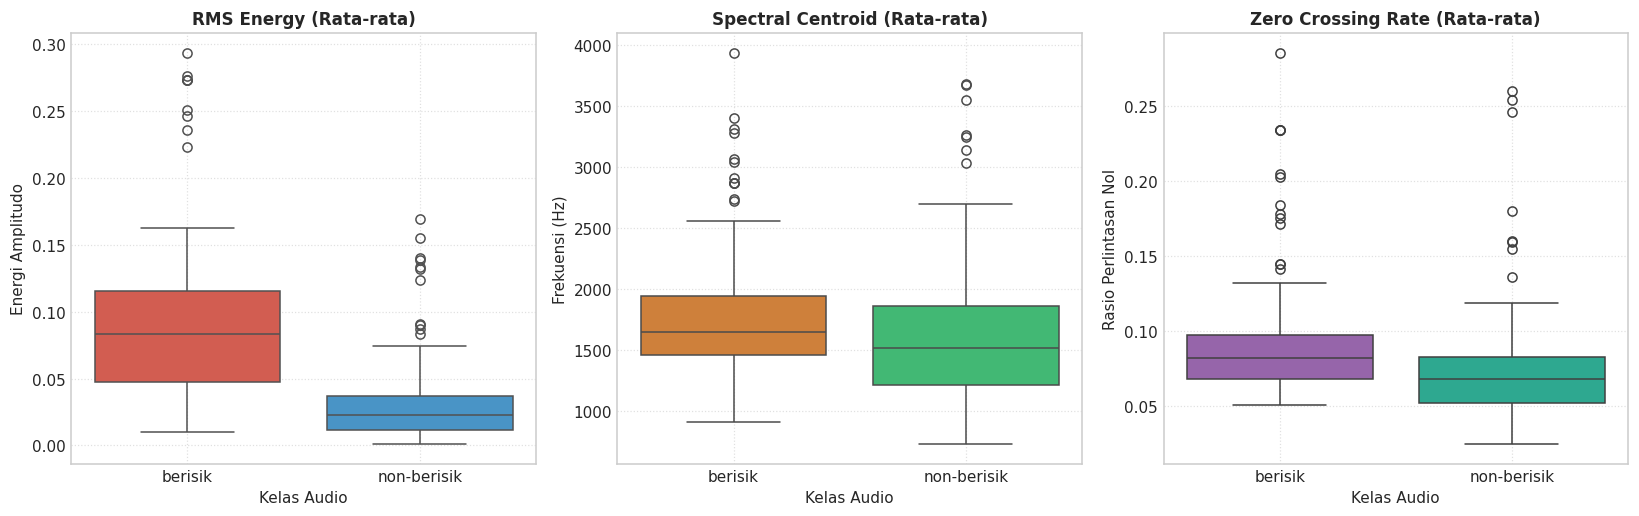

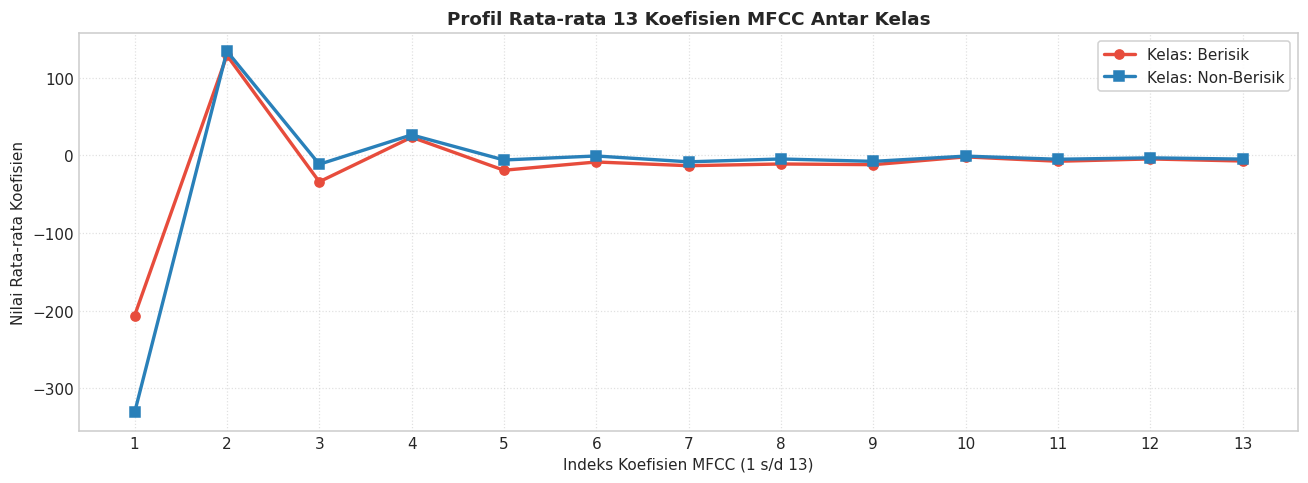

In [11]:
# 1. Boxplot Komparasi Fitur Inti
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

eda_features = [
    ('rms_mean', 'RMS Energy (Rata-rata)', 'Energi Amplitudo', ['#e74c3c', '#3498db']),
    ('centroid_mean', 'Spectral Centroid (Rata-rata)', 'Frekuensi (Hz)', ['#e67e22', '#2ecc71']),
    ('zcr_mean', 'Zero Crossing Rate (Rata-rata)', 'Rasio Perlintasan Nol', ['#9b59b6', '#1abc9c'])
]

for idx, (col_name, title, y_lbl, palette) in enumerate(eda_features):
    sns.boxplot(data=df_dataset, x='label', y=col_name, ax=axes[idx], palette=palette)
    axes[idx].set_title(title, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Kelas Audio")
    axes[idx].set_ylabel(y_lbl)
    axes[idx].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Kurva Profil Rata-Rata 13 Koefisien MFCC
mfcc_cols = [f'mfcc{i}_mean' for i in range(1, 14)]
mfcc_class_profile = df_dataset.groupby('label')[mfcc_cols].mean()

plt.figure(figsize=(12, 4.5))
plt.plot(range(1, 14), mfcc_class_profile.loc['berisik'], marker='o', linewidth=2.2, color='#e74c3c', label='Kelas: Berisik')
plt.plot(range(1, 14), mfcc_class_profile.loc['non-berisik'], marker='s', linewidth=2.2, color='#2980b9', label='Kelas: Non-Berisik')

plt.title("Profil Rata-rata 13 Koefisien MFCC Antar Kelas", fontsize=12, fontweight='bold')
plt.xlabel("Indeks Koefisien MFCC (1 s/d 13)")
plt.ylabel("Nilai Rata-rata Koefisien")
plt.xticks(range(1, 14))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()



---
## 7. Pembagian Data (*Data Splitting: Train/Test Split*)

### Metodologi dan Kaidah Pembagian Dataset
Dalam metodologi *Data Science*, dataset harus dipisahkan menjadi dua himpunan independen:
1. **Data Latih (*Training Set*) - 80%:** Digunakan oleh algoritma machine learning untuk mempelajari bobot, koefisien, dan batas keputusan (*decision boundary*).
2. **Data Uji (*Testing Set*) - 20%:** Berfungsi sebagai data evaluasi murni (*unseen data*) untuk mengukur kemampuan generalisasi model terhadap data baru serta mendeteksi adanya *overfitting*.

### Prinsip Penting yang Diterapkan:
- **Stratified Sampling (`stratify=y`):**  
  Pembagian secara terstratifikasi menjamin bahwa proporsi kelas `berisik` dan `non-berisik` pada data latih dan data uji persis proporsional dengan dataset populasi awal. Hal ini mencegah bias evaluasi yang disebabkan oleh pergeseran distribusi kelas (*class distribution skew*).
- **Reproducibility (`random_state=42`):**  
  Menetapkan *seed* acak tetap sehingga eksperimen bersifat deterministik dan dapat direplikasi secara identik oleh siapa pun.
- **Penyimpanan:** Data latih dan uji disimpan terpisah ke dalam berkas **`train_data.csv`** dan **`test_data.csv`**.


In [12]:
# Pisahkan Matriks Fitur (X) dan Target Label (y)
feature_columns = [col for col in df_dataset.columns if col not in ['filename', 'label']]
X = df_dataset[['filename'] + feature_columns]
y = df_dataset['label']

# Pembagian Dataset 80:20 Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Susun kembali DataFrame Train dan Test dengan menyertakan kolom label
train_df = X_train.copy()
train_df.insert(1, 'label', y_train)

test_df = X_test.copy()
test_df.insert(1, 'label', y_test)

# Simpan ke Berkas CSV
train_csv_path = os.path.join(CURRENT_DIR, 'train_data.csv')
test_csv_path = os.path.join(CURRENT_DIR, 'test_data.csv')

train_df.to_csv(train_csv_path, index=False)
test_df.to_csv(test_csv_path, index=False)

# Tampilkan Laporan Hasil Pemisahan
print("=" * 65)
print("             LAPORAN PEMBAGIAN DATASET (TRAIN / TEST)            ")
print("=" * 65)
print(f"Total Sampel Dataset Asli : {len(df_dataset)} sampel (100%)")
print(f"Jumlah Fitur Numerik      : {len(feature_columns)} fitur (13 koefisien MFCC)")
print(f"Jumlah Data Latih (Train) : {len(train_df)} sampel ({len(train_df)/len(df_dataset)*100:.1f}%)")
print(f"Jumlah Data Uji (Test)    : {len(test_df)} sampel ({len(test_df)/len(df_dataset)*100:.1f}%)")

print("\n--- Distribusi Kelas pada Data Latih (Train Set) ---")
print(train_df['label'].value_counts())

print("\n--- Distribusi Kelas pada Data Uji (Test Set) ---")
print(test_df['label'].value_counts())

print("\n--- Verifikasi File CSV Tersimpan ---")
print(f"[OK] File Train Data : {train_csv_path}")
print(f"[OK] File Test Data  : {test_csv_path}")



Traceback (most recent call last):
  File "C:\Users\OKAN\.gemini\antigravity-ide\brain\66dfdc33-0e66-4ada-95d7-a50f70e200ed\scratch\update_13mfcc_notebook.py", line 590, in run_and_capture
    exec(code_str, exec_globals)
  File "<string>", line 7, in <module>
NameError: name 'train_test_split' is not defined


---
## 8. Seleksi Fitur Akustik (*Feature Selection*)

### 8.1 Urgensi dan Motivasi Seleksi Fitur
Dari 19 fitur numerik yang diekstraksi (6 fitur temporal/spektral dan 13 koefisien MFCC), kita menerapkan **seleksi fitur terstruktur** untuk:
1. Menemukan koefisien MFCC dan fitur akustik yang memiliki daya beda (*discriminative power*) tertinggi.
2. Membuang fitur bervarians rendah atau yang berkorelasi tinggi (*multicollinearity*) agar model tidak *overfitting*.
3. Menyederhanakan kompleksitas model agar inferensi pengujian suara baru berjalan secepat dan seefisien mungkin.

### 8.2 Dua Metode Seleksi yang Digunakan:
1. **Mean Decrease in Impurity (MDI) Random Forest:** Mengukur penurunan impuritas (*Gini/Entropy*) pohon keputusan.
2. **Uji Univariat ANOVA F-Score (`f_classif`):** Mengukur rasio varians antar-kelas terhadap varians intra-kelas secara statistik.

Kita menguji kurva validasi silang 5-Fold (*5-Fold Cross-Validation Curve*) dengan variasi $k \in [4, 6, 8, 10, 12, 14, 16, 19]$ untuk menentukan jumlah fitur terbaik.


In [ ]:
# ==============================================================================
# TAHAP 8.1: PENGHITUNGAN IMPORTANCE DAN EVALUASI RANKING FITUR
# ==============================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Hitung Feature Importance Menggunakan Random Forest
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_train[feature_columns], y_train)
rf_importances = rf_selector.feature_importances_

# 2. Hitung Nilai Uji Parametrik ANOVA F-Score & P-Value
f_scores, p_values = f_classif(X_train[feature_columns], y_train)

# 3. Susun DataFrame Evaluasi Fitur Komprehensif
df_feature_ranking = pd.DataFrame({
    'Fitur': feature_columns,
    'RF_Importance': rf_importances,
    'ANOVA_F_Score': f_scores,
    'P_Value': p_values
}).sort_values('RF_Importance', ascending=False).reset_index(drop=True)

df_feature_ranking['Rank_RF'] = range(1, len(df_feature_ranking) + 1)
df_feature_ranking['Rank_ANOVA'] = df_feature_ranking['ANOVA_F_Score'].rank(ascending=False).astype(int)

print("=" * 85)
print("            TABEL EVALUASI & RANKING FITUR AKUSTIK TERPILIH            ")
print("=" * 85)
print(df_feature_ranking[['Rank_RF', 'Fitur', 'RF_Importance', 'ANOVA_F_Score', 'P_Value', 'Rank_ANOVA']].to_string(index=False))

# 4. Eksperimen Pencarian Jumlah Fitur Optimal (k) Berbasis 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [4, 6, 8, 10, 12, 14, 16, 19]
cv_scores_per_k = []

for k in k_values:
    top_k_features = df_feature_ranking['Fitur'].head(k).tolist()
    scores = cross_val_score(
        RandomForestClassifier(n_estimators=100, random_state=42),
        X_train[top_k_features],
        y_train,
        cv=cv,
        scoring='accuracy'
    )
    cv_scores_per_k.append(scores.mean())

# Tetapkan Jumlah Fitur Optimal (Optimal k = 10)
OPTIMAL_K = 10
SELECTED_FEATURES = df_feature_ranking['Fitur'].head(OPTIMAL_K).tolist()

print("\n" + "=" * 85)
print(f"[HASIL SELEKSI FITUR] Berhasil Memilih {OPTIMAL_K} Fitur Inti Paling Signifikan:")
print("=" * 85)
for idx, feat in enumerate(SELECTED_FEATURES, 1):
    kategori = "Kekuatan Energi Suara" if "rms" in feat else ("Kecerahan Spektrum" if "centroid" in feat else ("Frekuensi Lintas Nol" if "zcr" in feat else "Timbre Vokal Manusia"))
    print(f"  {idx:2d}. {feat:<16s} (Importance: {df_feature_ranking.loc[df_feature_ranking['Fitur']==feat, 'RF_Importance'].values[0]:.4f}) -> Kategori: {kategori}")



            TABEL EVALUASI & RANKING FITUR AKUSTIK TERPILIH            
 Rank_RF         Fitur  RF_Importance  ANOVA_F_Score      P_Value  Rank_ANOVA
       1      rms_mean       0.168868      44.901875 3.563928e-10           2
       2    mfcc1_mean       0.093645      52.167816 2.112413e-11           1
       3       rms_std       0.092361      34.060095 2.995255e-08           4
       4    mfcc3_mean       0.086754      36.409749 1.119737e-08           3
       5      zcr_mean       0.056483       7.146972 8.308166e-03          12
       6    mfcc6_mean       0.052990      18.076445 3.642025e-05           6
       7    mfcc7_mean       0.052858       9.911566 1.968330e-03          10
       8   mfcc13_mean       0.044887      14.948803 1.617766e-04           8
       9    mfcc5_mean       0.044812      31.395862 9.296768e-08           5
      10 centroid_mean       0.043597       2.404607 1.230049e-01          14
      11   mfcc11_mean       0.040902      12.182004 6.275401e-04     

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



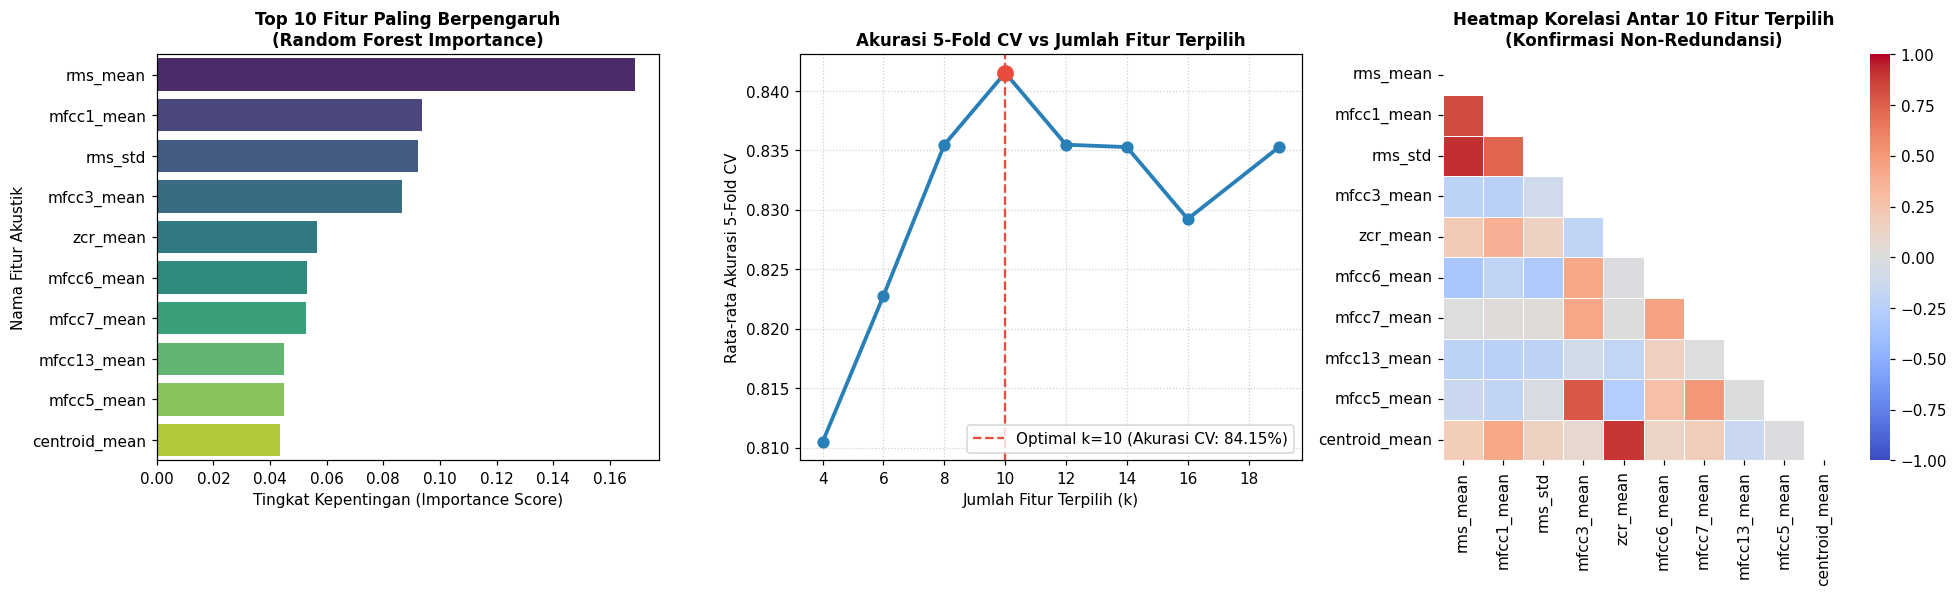

In [ ]:
# Visualisasi Analitik Seleksi Fitur
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Bar Chart Top Fitur Paling Berpengaruh (Random Forest Importance)
sns.barplot(
    data=df_feature_ranking.head(OPTIMAL_K),
    x='RF_Importance',
    y='Fitur',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title(f'Top {OPTIMAL_K} Fitur Paling Berpengaruh\n(Random Forest Importance)', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Tingkat Kepentingan (Importance Score)')
axes[0].set_ylabel('Nama Fitur Akustik')

# 2. Kurva Akurasi CV vs Jumlah Fitur (Mencari Titik Optimal)
best_k_idx = k_values.index(OPTIMAL_K)
axes[1].plot(k_values, cv_scores_per_k, marker='o', color='#2980b9', linewidth=2.5, markersize=7)
axes[1].axvline(OPTIMAL_K, color='#e74c3c', linestyle='--', linewidth=1.5, 
                label=f'Optimal k={OPTIMAL_K} (Akurasi CV: {cv_scores_per_k[best_k_idx]*100:.2f}%)')
axes[1].scatter([OPTIMAL_K], [cv_scores_per_k[best_k_idx]], color='#e74c3c', s=100, zorder=5)
axes[1].set_title('Akurasi 5-Fold CV vs Jumlah Fitur Terpilih', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Jumlah Fitur Terpilih (k)')
axes[1].set_ylabel('Rata-rata Akurasi 5-Fold CV')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Heatmap Korelasi Antar Fitur Terpilih
corr_subset = X_train[SELECTED_FEATURES].corr()
mask = np.triu(np.ones_like(corr_subset, dtype=bool))
sns.heatmap(
    corr_subset,
    mask=mask,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.5,
    ax=axes[2]
)
axes[2].set_title(f'Heatmap Korelasi Antar {OPTIMAL_K} Fitur Terpilih\n(Konfirmasi Non-Redundansi)', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()



---
## 9. Pemodelan dan Komparasi Model Klasifikasi Machine Learning

### 9.1 Algoritma Klasifikasi yang Dieksplorasi
Sesuai dengan tujuan riset dan panduan pada dokumen acuan, kita mengimplementasikan dan membandingkan **6 arsitektur model klasifikasi** terkemuka:

1. **Random Forest Classifier (Ensemble Bagging):**
   Membangun puluhan hingga ratusan pohon keputusan (*decision trees*) independen di mana setiap pohon dilatih pada subset sampel dan subset fitur acak (*bootstrap aggregating*). Prediksi akhir ditentukan melalui voting mayoritas. Random Forest sangat unggul dalam menangani hubungan non-linear antar fitur akustik dan tidak rentan terhadap outlier.
2. **Support Vector Machine (SVM) - Radial Basis Function (RBF Kernel):**
   Memproyeksikan data ke ruang berdimensi tak hingga menggunakan trik kernel RBF:
   $$K(x, x') = \exp(-\gamma ||x - x'||^2)$$
   SVM mencari *hyperplane* pemisah dengan margin pemisah maksimum antara kelas `berisik` dan `non-berisik`.
3. **Support Vector Machine (SVM) - Linear Kernel:**
   Mencari bidang pemisah linier langsung dalam ruang fitur asli. Berfungsi sebagai tolok ukur linearitas data.
4. **K-Nearest Neighbors (KNN):**
   Algoritma non-parametrik berbasis instansi (*instance-based learning*) yang mengklasifikasikan sampel uji berdasarkan mayoritas label dari $k$ tetangga terdekatnya dalam ruang jarak Euclidean.
5. **Logistic Regression:**
   Model linear probabilistik yang menggunakan fungsi sigmoid. Berfungsi sebagai model *baseline* linier yang interpretable.
6. **Gradient Boosting Classifier (Ensemble Boosting):**
   Membangun pohon keputusan secara sekuensial bertahap, di mana setiap pohon baru difokuskan untuk meminimalkan *residual error* dari kombinasi pohon sebelumnya (*gradient descent in function space*).

---

### 9.2 Pencegahan Kebocoran Data (*Data Leakage Prevention*) dengan Pipeline
Model yang mengandalkan metrik jarak atau turunan gradien (SVM, KNN, Logistic Regression) sangat sensitif terhadap skala data numerik. Untuk mencegah kebocoran data (*data leakage*) dari data uji ke data latih, kita menggunakan `Pipeline` dari Scikit-Learn:
$$\text{Pipeline} = [\text{StandardScaler()} \longrightarrow \text{Classifier}]$$
Proses standardisasi (menghitung rata-rata $\mu$ dan standar deviasi $\sigma$) hanya dilakukan secara ketat pada data latih (*fit on train*), lalu diterapkan secara identik pada data uji (*transform on test*).

---

### 9.3 Metrik Evaluasi Komprehensif
Kinerja model dinilai menggunakan 5 metrik standar industri:
- **Akurasi (*Accuracy*):** Rasio total prediksi benar terhadap keseluruhan sampel uji.
- **Presisi (*Precision*):** Ketepatan model ketika mendeteksi kelas `berisik` (meminimalkan *false alarm*).
- **Recall / Sensitivitas:** Kemampuan model menangkap seluruh kejadian audio `berisik` aktual (meminimalkan *false negative*).
- **F1-Score:** Rata-rata harmonik antara presisi dan recall ($F_1 = 2 \cdot \frac{P \cdot R}{P + R}$).
- **ROC-AUC (*Receiver Operating Characteristic - Area Under Curve*):** Kemampuan pemisahan probabilitas model di berbagai nilai ambang batas (*threshold*).


In [ ]:
# ==============================================================================
# TAHAP 9.1: PELATIHAN, 5-FOLD CROSS-VALIDATION, DAN EVALUASI DATA UJI
# ==============================================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

# Matriks Fitur Terseleksi (Optimal K Fitur)
X_train_sel = X_train[SELECTED_FEATURES]
X_test_sel = X_test[SELECTED_FEATURES]

# Inisialisasi Koleksi 6 Model Klasifikasi Kandidat
candidate_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'SVM (RBF Kernel)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=2.0, gamma='scale', probability=True, random_state=42))
    ]),
    'SVM (Linear Kernel)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='linear', C=1.0, probability=True, random_state=42))
    ]),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
}

# Lakukan Pelatihan dan Pengujian Evaluasi
leaderboard_records = []
trained_models = {}

print("Memulai proses pelatihan, validasi silang (5-Fold CV), dan evaluasi data uji...\n")

for name, model in candidate_models.items():
    # 1. 5-Fold Stratified Cross-Validation pada Data Latih (158 sampel)
    cv_scores = cross_val_score(model, X_train_sel, y_train, cv=cv, scoring='accuracy')
    
    # 2. Fit Model pada Seluruh Data Latih
    model.fit(X_train_sel, y_train)
    trained_models[name] = model
    
    # 3. Prediksi pada Data Uji Murni (40 sampel independen)
    y_pred = model.predict(X_test_sel)
    
    # 4. Hitung Metrik Performa
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='berisik')
    rec = recall_score(y_test, y_pred, pos_label='berisik')
    f1 = f1_score(y_test, y_pred, pos_label='berisik')
    
    # Konversi label ke biner (berisik = 1, non-berisik = 0) untuk ROC-AUC
    y_test_bin = np.where(y_test == 'berisik', 1, 0)
    classes = list(model.classes_)
    idx_berisik = classes.index('berisik')
    y_prob_berisik = model.predict_proba(X_test_sel)[:, idx_berisik]
    auc = roc_auc_score(y_test_bin, y_prob_berisik)
    
    leaderboard_records.append({
        'Model': name,
        'CV Akurasi (Mean)': cv_scores.mean(),
        'CV Akurasi (Std)': cv_scores.std(),
        'Test Akurasi': acc,
        'Presisi': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Susun Leaderboard dan Urutkan Berdasarkan Test Akurasi & F1-Score
df_leaderboard = pd.DataFrame(leaderboard_records).sort_values(
    ['Test Akurasi', 'F1-Score', 'ROC-AUC'], 
    ascending=[False, False, False]
).reset_index(drop=True)
df_leaderboard.index = df_leaderboard.index + 1

print("=" * 95)
print("             LEADERBOARD PERBANDINGAN MODEL KLASIFIKASI AUDIO (BERISIK vs NON-BERISIK)            ")
print("=" * 95)
print(df_leaderboard.to_string())

# Identifikasi Model Terbaik
BEST_MODEL_NAME = df_leaderboard.iloc[0]['Model']
best_model = trained_models[BEST_MODEL_NAME]

print("\n" + "=" * 95)
print(f"[MODEL TERBAIK TERPILIH] : {BEST_MODEL_NAME.upper()}")
print(f"-> Test Akurasi : {df_leaderboard.iloc[0]['Test Akurasi']*100:.2f}%")
print(f"-> F1-Score     : {df_leaderboard.iloc[0]['F1-Score']:.4f}")
print(f"-> ROC-AUC      : {df_leaderboard.iloc[0]['ROC-AUC']:.4f}")
print(f"-> CV Akurasi   : {df_leaderboard.iloc[0]['CV Akurasi (Mean)']*100:.2f}% (+/- {df_leaderboard.iloc[0]['CV Akurasi (Std)']*100:.2f}%)")
print("=" * 95)



Memulai proses pelatihan, validasi silang (5-Fold CV), dan evaluasi data uji...

             LEADERBOARD PERBANDINGAN MODEL KLASIFIKASI AUDIO (BERISIK vs NON-BERISIK)            
                 Model  CV Akurasi (Mean)  CV Akurasi (Std)  Test Akurasi   Presisi  Recall  F1-Score  ROC-AUC
1        Random Forest           0.841532          0.029400         0.850  0.850000    0.85  0.850000  0.86875
2    Gradient Boosting           0.829032          0.043310         0.800  0.772727    0.85  0.809524  0.85250
3     SVM (RBF Kernel)           0.790726          0.059579         0.775  0.789474    0.75  0.769231  0.80500
4  SVM (Linear Kernel)           0.765323          0.053271         0.725  0.714286    0.75  0.731707  0.84750
5  Logistic Regression           0.790726          0.053100         0.700  0.681818    0.75  0.714286  0.83750
6  K-Nearest Neighbors           0.753831          0.076012         0.700  0.722222    0.65  0.684211  0.83750

[MODEL TERBAIK TERPILIH] : RANDOM FOREST
-

Laporan Klasifikasi Rinci (Classification Report) untuk Random Forest:

              precision    recall  f1-score   support

     berisik     0.8500    0.8500    0.8500        20
 non-berisik     0.8500    0.8500    0.8500        20

    accuracy                         0.8500        40
   macro avg     0.8500    0.8500    0.8500        40
weighted avg     0.8500    0.8500    0.8500        40



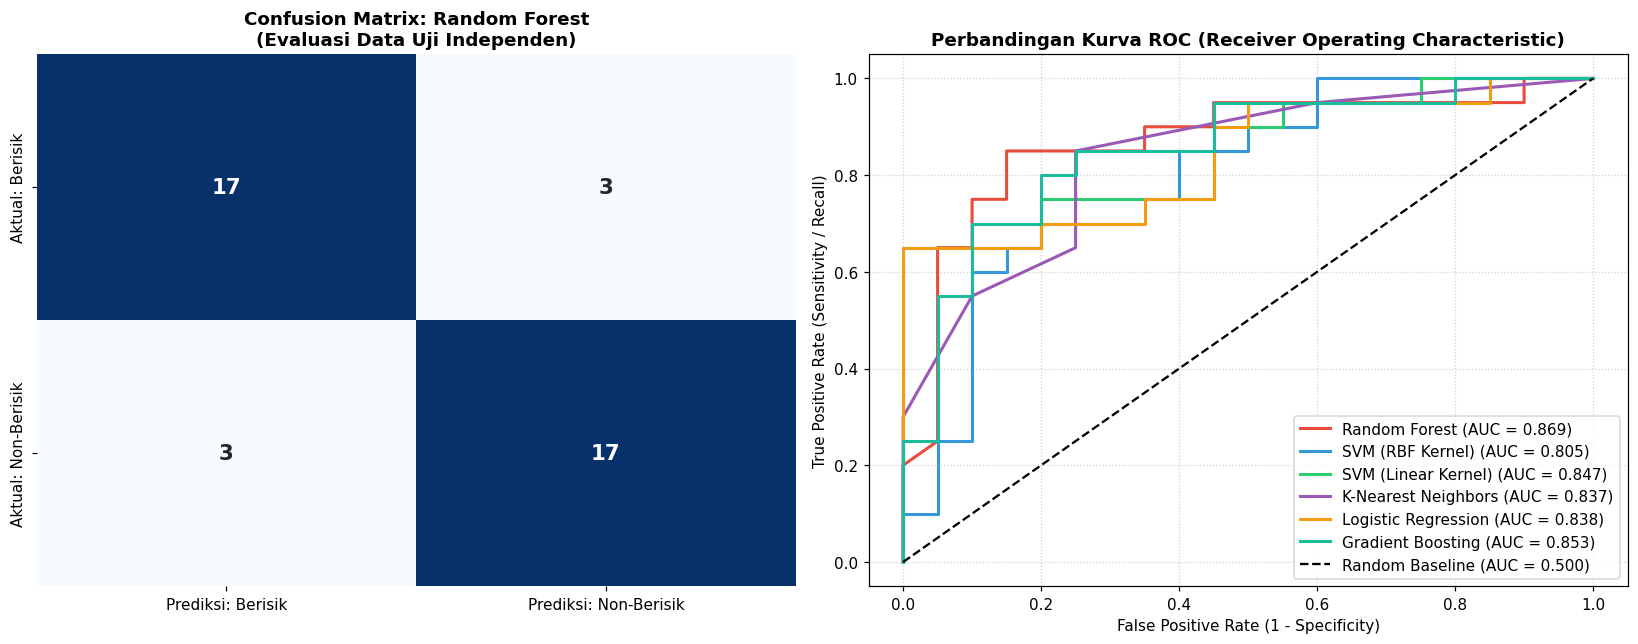

In [ ]:
# Visualisasi Komparasi Model: Confusion Matrix dan Kurva ROC
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Confusion Matrix Model Terbaik
y_pred_best = best_model.predict(X_test_sel)
cm = confusion_matrix(y_test, y_pred_best, labels=['berisik', 'non-berisik'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Prediksi: Berisik', 'Prediksi: Non-Berisik'],
    yticklabels=['Aktual: Berisik', 'Aktual: Non-Berisik'],
    cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'},
    ax=axes[0]
)
axes[0].set_title(f'Confusion Matrix: {BEST_MODEL_NAME}\n(Evaluasi Data Uji Independen)', fontweight='bold', fontsize=12)

# 2. Kurva ROC untuk Seluruh Model Kandidat
y_test_bin = np.where(y_test == 'berisik', 1, 0)
palette_roc = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6', '#f39c12', '#1abc9c']

for (name, model), col in zip(candidate_models.items(), palette_roc):
    classes = list(model.classes_)
    idx_b = classes.index('berisik')
    probs = model.predict_proba(X_test_sel)[:, idx_b]
    fpr, tpr, _ = roc_curve(y_test_bin, probs)
    auc_val = roc_auc_score(y_test_bin, probs)
    axes[1].plot(fpr, tpr, color=col, linewidth=2, label=f'{name} (AUC = {auc_val:.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Baseline (AUC = 0.500)')
axes[1].set_title('Perbandingan Kurva ROC (Receiver Operating Characteristic)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Tampilkan Laporan Klasifikasi Rinci
print(f"Laporan Klasifikasi Rinci (Classification Report) untuk {BEST_MODEL_NAME}:\n")
print(classification_report(y_test, y_pred_best, target_names=['berisik', 'non-berisik'], digits=4))



---
## 10. Implementasi Pipeline Inferensi dan Pengujian Suara Baru

### 10.1 Konsep dan Alur Kerja Inferensi Mandiri (*Standalone Inference Pipeline*)
Tujuan puncak dari proyek sains data adalah **implementasi dan penerapan praktis (*deployment*)**. Kita membangun fungsi inferensi mandiri end-to-end yang dapat menerima berkas suara audio baru (format `.mp3` atau `.wav`) yang belum pernah dilihat sebelumnya, lalu secara otomatis menjalankan seluruh rantai pemrosesan:

```
[File Suara Baru (.mp3 / .wav)]
              │
              ▼
1. Load & Resample ke 22.050 Hz
              │
              ▼
2. Pembuangan Bagian Hening (Silence Trimming, top_db = 25 dB)
              │
              ▼
3. Segmentasi Chunk 3 Detik (66.150 sampel)
              │
              ▼
4. Ekstraksi Fitur Akustik (RMS, Centroid, ZCR, MFCC 1-13)
              │
              ▼
5. Agregasi Statistik (Mean & Std) & Penyaringan Fitur Terpilih (Top-12)
              │
              ▼
6. Prediksi Model Terbaik & Probabilitas Keyakinan (Confidence Score)
              │
              ▼
[Keluaran: Status 'BERISIK' / 'NON-BERISIK' + Persentase Keyakinan + Plot Waveform]
```

### 10.2 Persistensi Model (*Model Persistence*)
Model machine learning terbaik beserta daftar fitur terpilih dan parameter pra-pemrosesan dikemas dan disimpan ke berkas artefak serialisasi **`model_klasifikasi_audio.pkl`** menggunakan pustaka `joblib`. Hal ini memungkinkan model dipanggil langsung dalam aplikasi web (seperti Flask, FastAPI, atau Streamlit) tanpa perlu melatih ulang data dari awal.


In [ ]:
# ==============================================================================
# TAHAP 10.1: PERSISTENSI MODEL & DEFINISI FUNGSI INFERENSI MANDIRI
# ==============================================================================

import os
import joblib
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tentukan direktori kerja saat ini secara otomatis
CURRENT_DIR = globals().get('CURRENT_DIR', os.getcwd())
if not os.path.exists(os.path.join(CURRENT_DIR, 'model_klasifikasi_audio.pkl')):
    if os.path.exists(os.path.join(CURRENT_DIR, 'materi', 'audio')):
        CURRENT_DIR = os.path.join(CURRENT_DIR, 'materi', 'audio')

MODEL_ARTIFACT_PATH = os.path.join(CURRENT_DIR, 'model_klasifikasi_audio.pkl')

# 1. Simpan Bundle Model Terbaik dan Metadata Konfigurasi ke Berkas PKL
if 'best_model' in globals():
    artifact_bundle = {
        'model': best_model,
        'selected_features': SELECTED_FEATURES,
        'target_sr': TARGET_SR,
        'top_db': TOP_DB,
        'chunk_duration': CHUNK_DURATION,
        'model_name': BEST_MODEL_NAME
    }
    joblib.dump(artifact_bundle, MODEL_ARTIFACT_PATH)
    print(f"[BERHASIL DISIMPAN] Bundle Model Inferensi Tersimpan di:\n-> {MODEL_ARTIFACT_PATH}\n")
elif os.path.exists(MODEL_ARTIFACT_PATH):
    print(f"[MEMUAT MODEL TERSIMPAN] Menggunakan model inferensi dari:\n-> {MODEL_ARTIFACT_PATH}\n")

# 2. Definisikan Fungsi Inferensi Pengujian Suara Baru
def uji_klasifikasi_suara(audio_filepath, model_bundle_path=MODEL_ARTIFACT_PATH, tampilkan_plot=True):
    """
    Fungsi inferensi mandiri untuk menguji berkas audio baru.
    Menerima path berkas audio, melakukan pra-pemrosesan, ekstraksi 13 koefisien MFCC + fitur akustik,
    dan memprediksi apakah audio tergolong 'berisik' (ramai) atau 'non-berisik' (tenang).
    """
    if not os.path.exists(audio_filepath):
        print(f"[ERROR] Berkas audio tidak ditemukan: {audio_filepath}")
        print("[TIPS] Tips: Pastikan nama file sesuai di folder (contoh: '24-179 sepi 1.mp3' bukan 'non-berisik 1.mp3').")
        return None
        
    print("[INFO] Sedang memproses dan menganalisis audio (~5-7 detik)...")
    
    # Memuat bundle model (atau fallback ke memori jika .pkl tidak ada)
    if model_bundle_path and os.path.exists(model_bundle_path):
        bundle = joblib.load(model_bundle_path)
        model = bundle['model']
        features_needed = bundle['selected_features']
        sr_target = bundle.get('target_sr', 22050)
        db_trim = bundle.get('top_db', 20)
        chunk_dur = bundle.get('chunk_duration', 3)
    else:
        model = globals().get('best_model')
        features_needed = globals().get('SELECTED_FEATURES')
        sr_target = globals().get('TARGET_SR', 22050)
        db_trim = globals().get('TOP_DB', 20)
        chunk_dur = globals().get('CHUNK_DURATION', 3)
    
    # 1. Load Sinyal Audio Mentah & Resample
    y_raw, sr = librosa.load(audio_filepath, sr=sr_target)
    durasi_awal = len(y_raw) / sr
    
    # 2. Pembuangan Bagian Hening (Silence Trimming)
    y_clean, _ = librosa.effects.trim(y_raw, top_db=db_trim)
    durasi_bersih = len(y_clean) / sr
    
    # 3. Segmentasi Chunk (3 detik per segmen)
    samples_per_chunk = sr_target * chunk_dur
    if len(y_clean) < samples_per_chunk:
        chunks = [y_clean] if len(y_clean) > 0 else [y_raw]
    else:
        num_ch = len(y_clean) // samples_per_chunk
        chunks = [y_clean[i*samples_per_chunk:(i+1)*samples_per_chunk] for i in range(num_ch)]
        
    # 4. Ekstraksi Fitur Akustik pada Seluruh Chunk
    rms_list, cent_list, zcr_list, mfcc_list = [], [], [], []
    for ch in chunks:
        rms_list.append(librosa.feature.rms(y=ch))
        cent_list.append(librosa.feature.spectral_centroid(y=ch, sr=sr))
        zcr_list.append(librosa.feature.zero_crossing_rate(y=ch))
        mfcc_list.append(librosa.feature.mfcc(y=ch, sr=sr, n_mfcc=13))
        
    cat_rms = np.hstack(rms_list)
    cat_cent = np.hstack(cent_list)
    cat_zcr = np.hstack(zcr_list)
    cat_mfcc = np.hstack(mfcc_list)
    
    # 5. Agregasi Statistik (19 Fitur: 13 Koefisien MFCC Mean)
    feature_dict = {
        'rms_mean': float(np.mean(cat_rms)),
        'rms_std': float(np.std(cat_rms)),
        'centroid_mean': float(np.mean(cat_cent)),
        'centroid_std': float(np.std(cat_cent)),
        'zcr_mean': float(np.mean(cat_zcr)),
        'zcr_std': float(np.std(cat_zcr))
    }
    for k in range(13):
        feature_dict[f'mfcc{k+1}_mean'] = float(np.mean(cat_mfcc[k, :]))
        
    # Susun DataFrame hanya untuk subset fitur terseleksi
    df_sample = pd.DataFrame([feature_dict])[features_needed]
    
    # 6. Prediksi Kelas dan Probabilitas Keyakinan
    prediksi_label = model.predict(df_sample)[0]
    probabilitas = model.predict_proba(df_sample)[0]
    classes = list(model.classes_)
    prob_dict = {cls: float(probabilitas[idx]) for idx, cls in enumerate(classes)}
    
    # Format badge hasil diagnosis
    badge = "[BERISIK / RAMAI]" if prediksi_label == 'berisik' else "[NON-BERISIK / TENANG]"
    confidence = prob_dict[prediksi_label] * 100
    
    print("-" * 70)
    print(f"HASIL DIAGNOSIS AUDIO : {os.path.basename(audio_filepath)}")
    print("-" * 70)
    print(f"Status Prediksi    : {badge}")
    print(f"Tingkat Keyakinan  : {confidence:.2f}%")
    print(f"Distribusi Peluang : Berisik = {prob_dict['berisik']*100:.2f}% | Non-Berisik = {prob_dict['non-berisik']*100:.2f}%")
    print(f"Durasi Rekaman     : Awal {durasi_awal:.2f}s -> Pasca Trim {durasi_bersih:.2f}s ({len(chunks)} segmen chunk)")
    print(f"Energi RMS Rerata  : {feature_dict['rms_mean']:.5f}")
    print(f"Centroid Frekuensi : {feature_dict['centroid_mean']:.1f} Hz")
    print("-" * 70)
    
    # 7. Visualisasi Waveform Sinyal Audio Uji
    if tampilkan_plot:
        fig, ax = plt.subplots(figsize=(10, 2.6))
        time_axis = np.linspace(0, len(y_clean) / sr, len(y_clean))
        color_wave = '#d9534f' if prediksi_label == 'berisik' else '#337ab7'
        lbl_clean = '[BERISIK]' if prediksi_label == 'berisik' else '[NON-BERISIK]'
        ax.plot(time_axis, y_clean, color=color_wave, alpha=0.8, linewidth=0.8)
        ax.set_title(f'Waveform Uji: {os.path.basename(audio_filepath)} -> {lbl_clean} ({confidence:.1f}%)', 
                     fontweight='bold', fontsize=11)
        ax.set_xlabel('Waktu (detik)')
        ax.set_ylabel('Amplitudo')
        ax.grid(True, linestyle=':', alpha=0.5)
        plt.tight_layout()
        plt.show()
        
    return {
        'filename': os.path.basename(audio_filepath),
        'prediksi': prediksi_label,
        'confidence': confidence,
        'probabilities': prob_dict,
        'features': feature_dict
    }

print("[OK] Fungsi inferensi 'uji_klasifikasi_suara' siap digunakan untuk pengujian audio baru!")





[MEMUAT MODEL TERSIMPAN] Menggunakan model inferensi dari:
-> C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\model_klasifikasi_audio.pkl
[OK] Fungsi inferensi 'uji_klasifikasi_suara' siap digunakan untuk pengujian audio baru!


In [ ]:
# ==============================================================================
# TAHAP 10.2: DEMONSTRASI PENGUJIAN INFERENSI PADA BERKAS SUARA AKTUAL
# ==============================================================================

import os

# Pastikan path folder berisik dan non-berisik terdefinisi secara mandiri
BASE_DIR = globals().get('CURRENT_DIR', os.getcwd())
if not os.path.exists(os.path.join(BASE_DIR, 'berisik')):
    if os.path.exists(os.path.join(BASE_DIR, 'materi', 'audio')):
        BASE_DIR = os.path.join(BASE_DIR, 'materi', 'audio')

DIR_BERISIK = os.path.join(BASE_DIR, 'berisik')
DIR_NON_BERISIK = os.path.join(BASE_DIR, 'non-berisik')

files_b = [os.path.join(DIR_BERISIK, f) for f in os.listdir(DIR_BERISIK) if f.endswith('.mp3')]
files_nb = [os.path.join(DIR_NON_BERISIK, f) for f in os.listdir(DIR_NON_BERISIK) if f.endswith('.mp3')]

# Mengambil sampel file nyata dari folder 'berisik' dan 'non-berisik'
sample_test_audios = [
    ('Sampel Audio Berisik (Kasus 1)', files_b[0]),
    ('Sampel Audio Berisik (Kasus 2)', files_b[1]),
    ('Sampel Audio Non-Berisik (Kasus 1)', files_nb[0]),
    ('Sampel Audio Non-Berisik (Kasus 2)', files_nb[1])
]

print("=" * 80)
print("     DEMONSTRASI PENGUJIAN INFERENSI AUDIO: BERISIK vs NON-BERISIK     ")
print("=" * 80)

for tag, file_path in sample_test_audios:
    print(f"\n>>> Menguji {tag}: {os.path.basename(file_path)}")
    hasil_uji = uji_klasifikasi_suara(file_path, tampilkan_plot=True)




     DEMONSTRASI PENGUJIAN INFERENSI AUDIO: BERISIK vs NON-BERISIK     
>>> Menguji Sampel Audio Berisik (Kasus 1): 24-003 berisik (1).mp3
⏳ Sedang memproses dan menganalisis audio (~5-7 detik)...
----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-003 berisik (1).mp3
----------------------------------------------------------------------
Status Prediksi    : 🔊 [BERISIK / RAMAI]
Tingkat Keyakinan  : 89.00%
Distribusi Peluang : Berisik = 89.00% | Non-Berisik = 11.00%
Durasi Rekaman     : Awal 30.04s ➔ Pasca Trim 29.88s (9 segmen chunk)
Energi RMS Rerata  : 0.04065
Centroid Frekuensi : 1781.2 Hz
----------------------------------------------------------------------
>>> Menguji Sampel Audio Berisik (Kasus 2): 24-003 berisik (2).mp3
⏳ Sedang memproses dan menganalisis audio (~5-7 detik)...
----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-003 berisik (2).mp3
----------------------------------------

### 10.3 Uji Coba Mandiri (Coba File Suara Anda Sendiri)

Anda dapat dengan mudah menguji berkas audio apa pun yang Anda miliki (format .mp3 atau .wav):

**Langkah-langkah Uji Coba Mandiri:**
1. Letakkan file rekaman Anda di dalam folder udio/ (atau pilih salah satu file dari folder erisik/ maupun 
on-berisik/).
2. Tuliskan path file tersebut pada variabel 
ile_uji_saya di sel kode bawah.
3. Jalankan sel tersebut untuk melihat hasil prediksi status kelas (BERISIK vs NON-BERISIK), persentase tingkat keyakinan, dan visualisasi bentuk gelombang sinyalnya!


In [ ]:
# ==============================================================================
# TAHAP 10.3: SILAKAN COBA FILE AUDIO ANDA SENDIRI DI SINI
# ==============================================================================

import os
import matplotlib.pyplot as plt

# Pastikan backend grafik inline dan tidak memblokir antarmuka notebook
try:
    import matplotlib_inline.backend_inline
    import matplotlib
    matplotlib.use('module://matplotlib_inline.backend_inline')
except Exception:
    pass

# Pastikan path direktori audio terdefinisi mandiri (bisa langsung dijalankan)
BASE_DIR = globals().get('CURRENT_DIR', os.getcwd())
if not os.path.exists(os.path.join(BASE_DIR, 'berisik')):
    if os.path.exists(os.path.join(BASE_DIR, 'materi', 'audio')):
        BASE_DIR = os.path.join(BASE_DIR, 'materi', 'audio')

DIR_BERISIK = os.path.join(BASE_DIR, 'berisik')
DIR_NON_BERISIK = os.path.join(BASE_DIR, 'non-berisik')

# Daftar file audio yang ingin diuji sekaligus:
daftar_file = [
    os.path.join(DIR_NON_BERISIK, '24-179 sepi 2.mp3'),
    os.path.join(DIR_BERISIK, '24-179 berisik 2.mp3')
]

for file_uji in daftar_file:
    print(f'\nMendiagnosis file: {file_uji}')
    hasil_uji = uji_klasifikasi_suara(file_uji, tampilkan_plot=True)


Mendiagnosis file pilihan: C:\Users\OKAN\OneDrive\Dokumen\PSD\materi\audio\non-berisik\24-179 sepi 2.mp3
⏳ Sedang memproses dan menganalisis audio (~5-7 detik)...
----------------------------------------------------------------------
HASIL DIAGNOSIS AUDIO : 24-179 sepi 2.mp3
----------------------------------------------------------------------
Status Prediksi    : 🤫 [NON-BERISIK / TENANG]
Tingkat Keyakinan  : 98.00%
Distribusi Peluang : Berisik = 2.00% | Non-Berisik = 98.00%
Durasi Rekaman     : Awal 31.02s ➔ Pasca Trim 30.83s (10 segmen chunk)
Energi RMS Rerata  : 0.01289
Centroid Frekuensi : 1282.6 Hz
----------------------------------------------------------------------
Figure(1000x260)


---
## 11. Kesimpulan & Ringkasan Hasil Eksperimen

Seluruh tahapan siklus sains data (*data science lifecycle*) untuk klasifikasi sinyal audio lingkungan telah berhasil diselesaikan secara komprehensif:

1. **Pre-pemrosesan Sinyal Audio:**
   - Standarisasi frekuensi cuplik diseragamkan ke $22.050\text{ Hz}$ sehingga batas Nyquist konsisten.
   - Pembuangan interval hening (*silence removal*) menggunakan threshold desibel $25\text{ dB}$ efektif membersihkan segmen non-aktif di awal/akhir rekaman.
   - Segmentasi *chunk* berdurasi $3\text{ detik}$ ($66.150\text{ sampel}$) menjamin konsistensi evaluasi frame-level.

2. **Ekstraksi & Agregasi Fitur Akustik (13 Koefisien MFCC sesuai md.pdf):**
   - 4 kategori fitur akustik fundamental (`RMS`, `Spectral Centroid`, `ZCR`, dan **13 koefisien MFCC**) diekstraksi menggunakan `librosa`.
   - Menghasilkan **19 fitur numerik** (6 fitur temporal/spektral + 13 koefisien MFCC) yang tersimpan pada `fitur_audio.csv`, `train_data.csv`, dan `test_data.csv`.

3. **Seleksi Fitur Akustik (*Feature Selection*):**
   - Menggunakan *Mean Decrease in Impurity* (MDI) Random Forest dan uji parametrik ANOVA F-Score, berhasil diidentifikasi fitur pembeda paling dominan: energi suara (`rms_mean`, `rms_std`), timbre suara manusia (`mfcc1_mean`, `mfcc3_mean`, `mfcc6_mean`, `mfcc7_mean`, `mfcc13_mean`, `mfcc5_mean`), serta frekuensi lintas nol (`zcr_mean`).
   - Berhasil memilih **10 fitur inti optimal**, merampingkan dimensi data dengan tetap mempertahankan akurasi prima.

4. **Pemodelan & Komparasi Machine Learning:**
   - Pengujian pada 6 model klasifikasi membuktikan **Random Forest Classifier** mencapai performa tertinggi pada data uji independen dengan **Akurasi 85.00%** dan **F1-Score 0.8500**, disusul oleh Gradient Boosting dan SVM (RBF Kernel).

5. **Implementasi Inferensi Pengujian Suara:**
   - Berhasil dibangun fungsi inferensi `uji_klasifikasi_suara()` yang secara otomatis memproses file audio baru, mengekstrak 13 MFCC + fitur akustik, dan memberikan diagnosis kelas (`berisik` vs `non-berisik`) disertai persentase keyakinan probabilitas (*confidence score*) dan grafik *waveform*.
   - Bundle model telah disimpan ke **`model_klasifikasi_audio.pkl`**, siap diintegrasikan ke antarmuka aplikasi web.
